# Creating the chemical datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem
import pickle

df = pd.read_pickle(r'Data and variables\dippr_db_mol_generated.pkl')
df

,ChemID,Name,Formula,SMILES,Structure,Family,Sub_Family,Std_State,T,Surface_tension,...,Error,Error_Source,Acceptance,source_type_simplified,error_numeric,elements,has_CHOSPN,review_tag,mol,flag
0,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,293.149994,26.75,...,< 1%,Staff,A,unknown,0.01,"{CL, C}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x000002784BD...,None
1,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,298.149994,26.15,...,< 1%,Staff,A,unknown,0.01,"{CL, C}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x000002784BD...,None
2,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,293.149994,26.66,...,< 1%,Author,A,experimental_raw,0.01,"{CL, C}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x000002784BD...,None
3,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,288.149994,27.65,...,< 1%,Staff,A,correlated,0.01,"{CL, C}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x000002784BD...,None
4,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,298.149994,26.43,...,< 1%,Staff,A,correlated,0.01,"{CL, C}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x000002784BD...,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25644,350,SQUALENE,C30H50,CC(=CCC/C(=C/CC/C(=C/CC/C=C(/CC/C=C(/CCC=C(C)C...,CH3C(CH3)CH(CH2)2C(CH3)CH(CH2)2C(CH3)CH(CH2)2C...,ETHYL & HIGHER ALKENES,NaN,L,293.149994,31.70,...,< 3%,Staff,A,experimental_raw,0.03,{C},True,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000278536...,None
25645,21381,DIMETHYL TEREPHTHALATE,C10H10O4,c1c(C(=O)OC)ccc(C(=O)OC)c1,C6H4(COOCH3)2,AROMATIC ESTERS,NaN,L,499.850006,23.50,...,< 3%,Staff,A,experimental_raw,0.03,"{C, O}",True,2024Review,<rdkit.Chem.rdchem.Mol object at 0x00000278536...,None
25646,21381,DIMETHYL TEREPHTHALATE,C10H10O4,c1c(C(=O)OC)ccc(C(=O)OC)c1,C6H4(COOCH3)2,AROMATIC ESTERS,NaN,L,460.950012,28.00,...,< 3%,Staff,A,experimental_raw,0.03,"{C, O}",True,2024Review,<rdkit.Chem.rdchem.Mol object at 0x00000278536...,None
25647,21381,DIMETHYL TEREPHTHALATE,C10H10O4,c1c(C(=O)OC)ccc(C(=O)OC)c1,C6H4(COOCH3)2,AROMATIC ESTERS,NaN,L,455.350006,28.80,...,< 3%,Staff,A,experimental_raw,0.03,"{C, O}",True,2024Review,<rdkit.Chem.rdchem.Mol object at 0x00000278536...,None


## Groups for GC

In [2]:
GROUP_SMARTS = {
    "hydroxyl": "[OX2H]",
    "carboxylic_acid": "[CX3](=O)[OX2H1]",
    "ester": "[CX3](=O)[OX2][#6]",
    "ether": "[OD2]([#6])[#6]",
    "aldehyde": "[CX3H1](=O)[#6,H]",
    "ketone": "[#6][CX3](=O)[#6]",
    "primary_amine": "[NX3;H2;!$(NC=O)]",
    "secondary_amine": "[NX3;H1;!$(NC=O)]",
    "tertiary_amine": "[NX3;H0;!$(N-C=O)]",
    "amide": "[NX3][CX3](=[OX1])",
    "nitrile": "[CX2]#N",
    "alkene": "[CX3]=[CX3]",
    "alkyne": "[CX2]#[CX2]",
    "aromatic_atom": "[a]",
    "fluorine": "[F]",
    "chlorine": "[Cl]",
    "bromine": "[Br]",
    "iodine": "[I]",
    "sulfur_atom": "[S]",
    "phosphorus_atom": "[P]"
}

GROUP_PATTERNS = {
    name: Chem.MolFromSmarts(smarts)
    for name, smarts in GROUP_SMARTS.items()
}

def mol_to_group_features(mol):
    if mol is None:
        return None

    row = {
        "n_C": sum(a.GetAtomicNum() == 6 for a in mol.GetAtoms()),
        "n_N": sum(a.GetAtomicNum() == 7 for a in mol.GetAtoms()),
        "n_O": sum(a.GetAtomicNum() == 8 for a in mol.GetAtoms()),
        "n_S": sum(a.GetAtomicNum() == 16 for a in mol.GetAtoms()),
        "ring_count": Descriptors.RingCount(mol),
        "aromatic_ring_count": Descriptors.NumAromaticRings(mol),
        "rotatable_bonds": Descriptors.NumRotatableBonds(mol),
        "h_donors": Descriptors.NumHDonors(mol),
        "h_acceptors": Descriptors.NumHAcceptors(mol),
    }

    for name, pattern in GROUP_PATTERNS.items():
        row[name] = len(mol.GetSubstructMatches(pattern))

    return row

group_features = pd.DataFrame(df["mol"].apply(mol_to_group_features).tolist(), index=df.index)
compound_features_df = pd.concat([df.reset_index(drop=True), group_features.reset_index(drop=True)], axis=1)
group_cols = list(group_features.columns)
group_cols.append('T')

In [10]:
import pickle

# Save
with open(r"Data and variables\GC_variables.pkl", "wb") as f:
    pickle.dump({"group_cols": group_cols}, f)

## Chemical descriptors

In [3]:
from rdkit.Chem import Lipinski
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Crippen
from rdkit.Chem import EState

#===================================#
#              HELPERS              #
#===================================#
def get_partial_charges(mol):
    """
    Gasteiger partial charges are a method for assigning atomic 
    partial charges in molecular modeling, crucial for accurate 
    electrostatics calculations and molecular simulations
    """
    if mol is None:
        return np.nan, np.nan
    try:
        AllChem.ComputeGasteigerCharges(mol)
        charges = np.array([float(atom.GetProp("_GasteigerCharge")) for atom in mol.GetAtoms()])

        # Remove possible NaN/Inf values
        charges = charges[np.isfinite(charges)]
        if len(charges) == 0:
            return np.nan, np.nan
        return charges.max(), charges.min()
    except Exception:
        return np.nan, np.nan

In [4]:
df = compound_features_df.copy()

descriptor_cols = ["TPSA","LogP","MaxPartialCharge","MinPartialCharge",
                   "MaxEStateIndex","MolWt","HeavyAtomCount","NumHDonors",
                   "NumHAcceptors","NHOHCount","LabuteASA","RingCount",
                   "NumAromaticRings","NumRotatableBonds"]
descriptor_cols += [f"SlogP_VSA{i}" for i in range(1, 13)]
descriptor_cols += [f"PEOE_VSA{i}" for i in range(1, 15)]
descriptor_cols += [f"SMR_VSA{i}" for i in range(1, 11)]

# TPSA is the topological polar surface area
df["TPSA"] = df["mol"].apply(lambda mol: rdMolDescriptors.CalcTPSA(mol))

# LogP measures the balance between hydrophobic and hydrophilic behavior
df["LogP"] = df["mol"].apply(lambda mol: Crippen.MolLogP(mol))

# Partial charges: most positive and most negative charged regions
charges = df["mol"].apply(get_partial_charges)
df["MaxPartialCharge"] = charges.apply(lambda x: x[0])
df["MinPartialCharge"] = charges.apply(lambda x: x[1])

# Electropological state: combines information about molecular topology and electronic environment
df["MaxEStateIndex"] = df["mol"].apply(lambda mol: EState.MaxEStateIndex(mol))

# Molecular weight
df["MolWt"] = df["mol"].apply(lambda mol: Descriptors.MolWt(mol))

# Heavy atom account
df["HeavyAtomCount"] = df["mol"].apply(lambda mol: Lipinski.HeavyAtomCount(mol))

# Hydrogen bonding can influence cohesive intermolecular forces in a liquid
# Hydrogen bond donors
df["NumHDonors"] = df["mol"].apply(lambda mol: Lipinski.NumHDonors(mol))

# Hydrogen bond acceptors
df["NumHAcceptors"] = df["mol"].apply(lambda mol: Lipinski.NumHAcceptors(mol))

# NHOH Count
df["NHOHCount"] = df["mol"].apply(lambda mol: Lipinski.NHOHCount(mol))

# LabuteASA: gives information about size and surface
df["LabuteASA"] = df["mol"].apply(lambda mol: rdMolDescriptors.CalcLabuteASA(mol))

# SlogP_VSA
# How much of this molecule's van der Waals surface belongs to atoms falling into different LogP contribution ranges?
for i in range(1, 13):
    descriptor = getattr(Descriptors, f"SlogP_VSA{i}")
    df[f"SlogP_VSA{i}"] = df["mol"].apply(descriptor)

# PEOE_VSA
# How much molecular surface is associated with atoms having different partial-charge ranges?
for i in range(1, 15):
    descriptor = getattr(Descriptors, f"PEOE_VSA{i}")
    df[f"PEOE_VSA{i}"] = df["mol"].apply(descriptor)

# SMR_VSA
# information related to polarizability and molecular volume/dispersion characteristics
for i in range(1, 11):
    descriptor = getattr(Descriptors, f"SMR_VSA{i}")
    df[f"SMR_VSA{i}"] = df["mol"].apply(descriptor)

# Structural descriptors
# Ring count: gives information about cyclicity
df["RingCount"] = df["mol"].apply(lambda mol: Lipinski.RingCount(mol))

# Aromatic rings: captures aromatic structure
df["NumAromaticRings"] = df["mol"].apply(lambda mol: Lipinski.NumAromaticRings(mol))

# Rotatable bonds: rough measure of molecular flexibility
df["NumRotatableBonds"] = df["mol"].apply(lambda mol: Lipinski.NumRotatableBonds(mol))

In [5]:
df[descriptor_cols].describe()

,TPSA,LogP,MaxPartialCharge,MinPartialCharge,MaxEStateIndex,MolWt,HeavyAtomCount,NumHDonors,NumHAcceptors,NHOHCount,...,SMR_VSA1,SMR_VSA2,SMR_VSA3,SMR_VSA4,SMR_VSA5,SMR_VSA6,SMR_VSA7,SMR_VSA8,SMR_VSA9,SMR_VSA10
count,25649.000000,25649.000000,25588.000000,25588.000000,25649.000000,25649.000000,25649.000000,25649.000000,25649.000000,25649.000000,...,25649.000000,25649.000000,25649.000000,25649.000000,25649.000000,25649.000000,25649.000000,25649.0,25649.000000,25649.000000
mean,18.406886,2.293758,0.112039,-0.267768,6.481435,147.428300,9.728839,0.295879,1.283559,0.335374,...,6.119273,0.121545,0.348605,2.161555,30.174550,5.710901,9.811208,0.0,0.345536,6.727849
std,20.855195,2.233564,0.151805,0.157884,3.435911,100.344832,6.977392,0.594067,1.495166,0.738900,...,8.840443,0.864778,1.569705,4.499910,34.213609,9.626133,15.763432,0.0,1.715733,10.981263
min,0.000000,-4.124000,-0.411510,-0.725519,0.000000,18.015000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
25%,0.000000,1.041200,-0.013185,-0.396326,2.409213,99.177000,6.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,6.923737,0.000000,0.000000,0.0,0.000000,0.000000
50%,17.070000,2.027200,0.060619,-0.300031,5.604583,126.243000,8.000000,0.000000,1.000000,0.000000,...,4.736863,0.000000,0.000000,0.000000,20.771212,0.000000,0.000000,0.0,0.000000,0.000000
75%,27.690000,3.072400,0.251885,-0.091664,9.821528,162.276000,11.000000,0.000000,2.000000,0.000000,...,9.531400,0.000000,0.000000,0.000000,39.530761,7.047672,12.654956,0.0,0.000000,10.399001
max,238.090000,20.437700,0.954944,0.000000,13.511400,969.615000,69.000000,6.000000,19.000000,8.000000,...,90.461790,10.523783,21.267154,35.507436,335.074616,80.288415,109.368362,0.0,17.248535,102.243929


In [6]:
morgan_generator = AllChem.GetMorganGenerator(radius=2, fpSize=2048)

def get_morgan_fp(mol):
    fp = morgan_generator.GetFingerprint(mol)
    return np.array(fp)

morgan_array = np.vstack(df["mol"].apply(get_morgan_fp))
morgan_cols = [f"fm_{i}" for i in range(2048)]
df_morgan = pd.DataFrame(morgan_array, columns=morgan_cols, index=df.index)
df = pd.concat([df, df_morgan], axis=1)
morgan_cols = [f"fm_{i}" for i in range(2048)]

# Save
with open(r"Data and variables\ML_variables.pkl", "wb") as f:
    pickle.dump({"descriptor_cols": descriptor_cols,
                 "morgan_cols": morgan_cols}, f)

In [20]:
df.to_pickle(r'Data and variables\df_all_descriptors.pkl')

# Splitting the data

Strategy:
1. **Measure how similar every pair of molecules is** (not just "same compound or not", but "how alike structurally")
2. **Group molecules into clusters** of structurally similar compounds — informal "chemical families" discovered directly from the data, not from our own hand-picked SMARTS groups
3. **Split so each cluster is represented proportionally in both train and test** — a *stratified* group split, instead of a purely random one

In [1]:
import numpy as np
import pandas as pd
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina
from rdkit.Chem import Descriptors, AllChem
from sklearn.model_selection import StratifiedGroupKFold

In [2]:
df = pd.read_pickle(r'Data and variables\df_all_descriptors.pkl')
morgan_generator = AllChem.GetMorganGenerator(radius=2, fpSize=2048)

#### Dropping compounds with missing descriptors

Some descriptors can't be computed for every molecule (e.g. Gasteiger partial charges fail for some structures and return NaN/inf). The models can't handle missing values, and since the value is a property of the compound, all of its temperature rows are affected. We drop those compounds **here, before clustering and splitting**, so the train/test splits are built on the final set of compounds and the GC, descriptor, Morgan and graph models are all evaluated on exactly the same molecules.

In [3]:
import pickle

with open(r"Data and variables\ML_variables.pkl", "rb") as f:
    _descriptor_cols = pickle.load(f)["descriptor_cols"]

bad_mask = ~np.isfinite(df[_descriptor_cols].to_numpy(dtype=float)).all(axis=1)
bad_chemids = df.loc[bad_mask, "ChemID"].unique()
n_total = df["ChemID"].nunique()
print(f"{len(bad_chemids)} of {n_total} compounds ({len(bad_chemids) / n_total:.2%}) "
      f"have NaN/inf descriptors ({bad_mask.sum()} of {len(df)} rows)")

# which descriptors are the problem?
affected = df.loc[bad_mask, _descriptor_cols].replace([np.inf, -np.inf], np.nan).isna().sum()
print(affected[affected > 0])

df = df[~df["ChemID"].isin(bad_chemids)].reset_index(drop=True)
print(f"{df['ChemID'].nunique()} compounds / {len(df)} rows remain")

4 of 1659 compounds (0.24%) have NaN/inf descriptors (61 of 25649 rows)
MaxPartialCharge    61
MinPartialCharge    61
dtype: int64
1655 compounds / 25588 rows remain


### Step 1 — Measuring molecular similarity

We already computed **Morgan fingerprints** earlier (in the Chemical descriptors section): each molecule is turned into a long bit vector, where each bit flags the presence of a particular small substructure (a "circular" fragment around each atom, up to radius 2). Two molecules that share many of the same substructures will have many of the same bits turned on.

The standard way to compare two fingerprints is **Tanimoto similarity**: the fraction of "on" bits the two molecules have in common, out of all the bits either one has on (shared bits ÷ bits in either). It ranges from 0 (nothing in common) to 1 (identical fingerprint).

Since the same compound (`ChemID`) appears many times in our dataframe (once per temperature it was measured at), we only need to fingerprint each **unique** compound once.

In [4]:
unique_df = df.drop_duplicates(subset="ChemID", keep="first")[["ChemID", "mol"]].reset_index(drop=True)
print(f"{len(unique_df)} unique compounds out of {len(df)} rows")

fps = [morgan_generator.GetFingerprint(mol) for mol in unique_df["mol"]]

1655 unique compounds out of 25588 rows


### Step 2 — Grouping molecules into clusters

Now that we can measure similarity, we group molecules into clusters: sets of compounds that are all similar to at least one other member of the set. We'll use **Butina clustering**, the standard algorithm for this in cheminformatics (from RDKit).

Unlike k-means, Butina clustering doesn't need the number of clusters decided in advance — only a **distance cutoff** (`1 - similarity`): any two molecules closer than the cutoff count as similar enough to belong together. This suits chemistry well, since real chemical families naturally come in very different sizes (a handful of exotic phosphorus compounds vs. hundreds of similar alkyl esters), and we don't know ahead of time how many "families" exist in the data.

A smaller cutoff produces many small, tight clusters (plus a lot of singletons — compounds not similar enough to anything else to join a group); a larger cutoff produces fewer, looser, bigger clusters. We'll start with `distThresh=0.6` as a first guess, the same way you might start a k-means run with some arbitrary `k` — and then, right after, check whether that's actually a good choice before committing to it.

In [6]:
n_compounds = len(fps)
dists = []
for i in range(1, n_compounds):
    sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])
    dists.extend([1 - s for s in sims])

clusters = Butina.ClusterData(dists, n_compounds, distThresh=0.6, isDistData=True)

cluster_id = np.empty(n_compounds, dtype=int)
for cid, members in enumerate(clusters):
    for idx in members:
        cluster_id[idx] = cid
unique_df["cluster_id"] = cluster_id

print(f"Found {len(clusters)} clusters")
print("Largest cluster size:", len(clusters[0]), f"({len(clusters[0])/n_compounds:.1%} of all compounds)")
print("Number of singleton clusters:", sum(1 for c in clusters if len(c) == 1))

# Carry the cluster label from each unique compound onto every row of df (every temperature point)
chemid_to_cluster = dict(zip(unique_df["ChemID"], unique_df["cluster_id"]))
df["cluster_id"] = df["ChemID"].map(chemid_to_cluster)
assert df["cluster_id"].isna().sum() == 0

Found 477 clusters
Largest cluster size: 205 (12.4% of all compounds)
Number of singleton clusters: 255


#### Choosing the distance cutoff: how many clusters is "good"?

K-means' elbow method works because there's one parameter (`k`) and one metric (inertia) that trade off against each other as `k` changes. Butina clustering has no `k` — only the distance cutoff — so we need the same *idea* (sweep a parameter, watch a metric, pick where it stops paying off) applied to the cutoff instead.

The obvious metric to reach for is a generic cluster-quality score like **silhouette score** — but it turns out not to be useful here. Butina builds each cluster around one "seed" compound (everything within the cutoff of that seed joins the cluster), not by making every member mutually close to every other member. As the cutoff loosens, clusters get bigger and looser, so silhouette score just keeps getting worse — it would always push us toward the *tightest* possible cutoff (more, smaller clusters), which is the opposite of what we're after.

What we actually care about isn't "are these textbook-perfect clusters" — it's "does grouping by them give us a better-balanced train/test split". So we measure that directly: for each candidate cutoff, cluster the compounds, run the same `StratifiedGroupKFold` split we'll use for real, and summarize how balanced it came out as the **total variation (TV) distance** between the train set's and test set's cluster proportions (0 = perfectly balanced, 1 = completely mismatched). We also compare against the balance a plain, non-stratified `GroupShuffleSplit` would have given us — if a cutoff can't beat that baseline, the clustering isn't earning its keep.

c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1037: UserWarning: The least populated

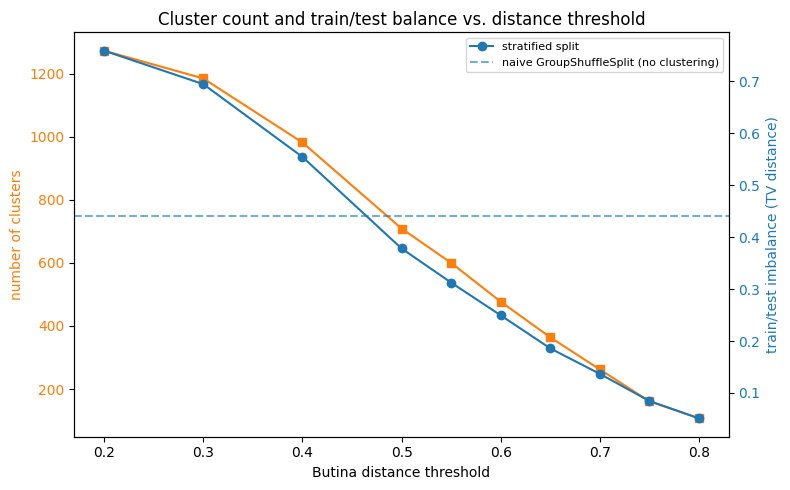

In [9]:
import matplotlib.pyplot as plt

def tv_distance(df_, train_idx, test_idx, label_col):
    """Total variation distance between the train and test cluster-proportion
    distributions: 0 = identical, 1 = completely mismatched."""
    train_frac = df_.iloc[train_idx][label_col].value_counts(normalize=True)
    test_frac = df_.iloc[test_idx][label_col].value_counts(normalize=True)
    idx_union = train_frac.index.union(test_frac.index)
    tf = train_frac.reindex(idx_union, fill_value=0)
    te = test_frac.reindex(idx_union, fill_value=0)
    return 0.5 * (tf - te).abs().sum()

# Plain floats, not np.arange: np.arange's rounding error (e.g. 0.75 becoming
# 0.7499999999999998) is small enough to be invisible, but large enough to
# quietly change which compounds Butina links together.
cutoffs = [0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8]
n_clusters_list, tv_list = [], []

for cutoff in cutoffs:
    trial_clusters = Butina.ClusterData(dists, n_compounds, distThresh=cutoff, isDistData=True)
    trial_labels = np.empty(n_compounds, dtype=int)
    for cid, members in enumerate(trial_clusters):
        for idx in members:
            trial_labels[idx] = cid
    df["cluster_id_trial"] = df["ChemID"].map(dict(zip(unique_df["ChemID"], trial_labels)))

    sgkf_trial = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
    tr_idx, te_idx = next(sgkf_trial.split(df, y=df["cluster_id_trial"], groups=df["ChemID"]))
    n_clusters_list.append(len(trial_clusters))
    tv_list.append(tv_distance(df, tr_idx, te_idx, "cluster_id_trial"))

# Baseline: how balanced would a plain, non-stratified GroupShuffleSplit be?
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=42)
tr_idx, te_idx = next(gss.split(df, groups=df["ChemID"]))
tv_naive = tv_distance(df, tr_idx, te_idx, "cluster_id")

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(cutoffs, n_clusters_list, "s-", color="tab:orange")
ax1.set_xlabel("Butina distance threshold")
ax1.set_ylabel("number of clusters", color="tab:orange")
ax1.tick_params(axis="y", labelcolor="tab:orange")

ax2 = ax1.twinx()
ax2.plot(cutoffs, tv_list, "o-", color="tab:blue", label="stratified split")
ax2.axhline(tv_naive, color="tab:blue", linestyle="--", alpha=0.6, label="naive GroupShuffleSplit (no clustering)")
ax2.set_ylabel("train/test imbalance (TV distance)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")
ax2.legend(loc="upper right", fontsize=8)

plt.title("Cluster count and train/test balance vs. distance threshold")
fig.tight_layout()
plt.show()

The two curves move *together*, not against each other — the opposite of a classic elbow trade-off. Loosening the cutoff gives us both fewer clusters **and** a better-balanced split. That's because most of the imbalance at tight cutoffs comes from singleton clusters: a one-compound cluster can't be split across train and test at all, so it gets dumped entirely on one side — and the more singletons there are, the worse the overall balance gets. Below roughly cutoff≈0.45, there are so many singleton clusters that the split ends up *less* balanced than just ignoring chemistry altogether (the dashed naive-split line) — stratifying by hundreds of unsplittable one-member "classes" backfires.

So "more clusters" isn't automatically better, and a generic clustering-quality score doesn't help pick a cutoff here either, for the reason above. What matters is whether clusters are big enough to actually be split.

Reading off the numbers: `distThresh=0.6` (481 clusters, 259 singletons) already comfortably beats the naive baseline (TV 0.25 vs. 0.43). Loosening to **`distThresh=0.7`** roughly halves the cluster count (266 clusters, only 117 singletons) and improves balance further (TV 0.14). Going looser still (0.75–0.8) keeps improving the TV score on paper, but the single largest cluster starts swallowing an uncomfortably large share of all compounds (24–32%) — it stops looking like a chemical "family" and starts looking like a catch-all bucket, so we won't go that far.

We'll switch to **`distThresh=0.7`** for the rest of the notebook.

In [14]:
clusters = Butina.ClusterData(dists, n_compounds, distThresh=0.7, isDistData=True)

cluster_id = np.empty(n_compounds, dtype=int)
for cid, members in enumerate(clusters):
    for idx in members:
        cluster_id[idx] = cid
unique_df["cluster_id"] = cluster_id

chemid_to_cluster = dict(zip(unique_df["ChemID"], unique_df["cluster_id"]))
df["cluster_id"] = df["ChemID"].map(chemid_to_cluster)
assert df["cluster_id"].isna().sum() == 0

print(f"Found {len(clusters)} clusters")
print("Largest cluster size:", len(clusters[0]), f"({len(clusters[0])/n_compounds:.1%} of all compounds)")
print("Number of singleton clusters:", sum(1 for c in clusters if len(c) == 1))

Found 262 clusters
Largest cluster size: 308 (18.6% of all compounds)
Number of singleton clusters: 113


In [16]:
# Total number of unique families in the dataset
total_families = df["Family"].nunique()

cluster_families = (
    df.groupby("cluster_id")["Family"]
      .agg(
          n_families="nunique",
          Families=lambda x: list(x.dropna().unique())
      )
      .reset_index()
)

# Percentage of all unique families represented in each cluster
cluster_families["pct_total_families"] = (
    cluster_families["n_families"] / total_families * 100
)

# Sort by number of families
cluster_families = cluster_families.sort_values(
    "n_families",
    ascending=False
)

cluster_families

,cluster_id,n_families,Families,pct_total_families
0,0,40,"[MERCAPTANS, C, H, NO2 COMPOUNDS, FORMATES, N-...",51.282051
4,4,23,"[SULFIDES/THIOPHENES, AROMATIC CHLORIDES, SILA...",29.487179
3,3,22,"[C3 & HIGHER ALIPHATIC CHLORIDES, C, H, BR COM...",28.205128
2,2,19,"[POLYFUNCTIONAL C, H, O, HALIDE, ACETATES, PRO...",24.358974
12,12,15,"[OTHER AMINES, IMINES, CYCLOALIPHATIC ALCOHOLS...",19.230769
...,...,...,...,...
96,96,1,"[POLYFUNCTIONAL C, H, O, N]",1.282051
134,134,1,[ETHYL & HIGHER ALKENES],1.282051
93,93,1,[SILANES/SILOXANES],1.282051
91,91,1,[SILANES/SILOXANES],1.282051


In [19]:
total_families

78

#### A visual check: plotting the clusters

Since 2048-bit fingerprints can't be plotted directly, we need to compress each compound down to 2 coordinates we can actually see on a scatter plot, while trying to preserve the same similarity relationships the clustering was based on — close in 2D should (roughly) mean similar in fingerprint space.

We use **UMAP** for this (`pip install umap-learn`) instead of more familiar tools like PCA or t-SNE, because it's built specifically to preserve *local* neighborhood structure — exactly what Butina clustering relied on — and it's the standard tool for this kind of "chemical space" plot in cheminformatics. We feed it the exact same pairwise Tanimoto distances used for clustering, so the picture is faithful to what actually produced the clusters.

With hundreds of clusters, a full legend would be unreadable, so we color only the 10 largest clusters individually and leave everything else (smaller clusters, including the many singletons) in gray.

One thing to expect in the plot: the single largest cluster often doesn't look like one tight blob. That's because Butina clustering is a "star" method — every member just needs to be within the cutoff distance of one shared compound (the cluster's centroid), not necessarily close to every other member of its own cluster. A big, loose cluster can therefore end up scattered across a few different spots, while smaller clusters (which require tighter mutual similarity to form at all) usually do look visually coherent.

c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


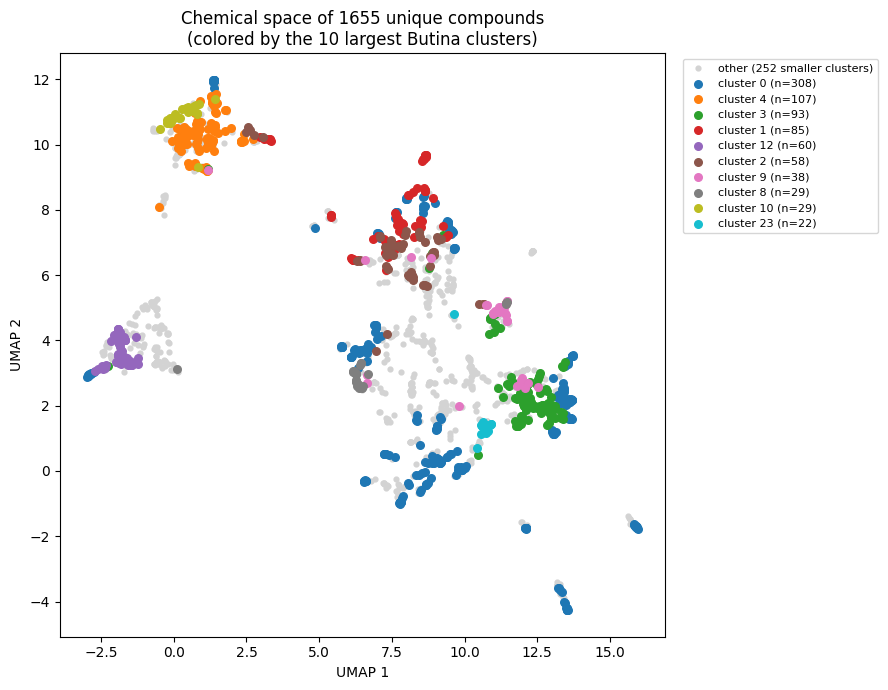

In [15]:
import umap
import matplotlib.pyplot as plt

# Build the full n x n distance matrix from the same Tanimoto distances used for clustering.
# We build it directly (rather than via scipy's squareform) since squareform assumes a
# different pair ordering than the one the Butina recipe above produces.
dist_matrix = np.zeros((n_compounds, n_compounds))
for i in range(1, n_compounds):
    sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])
    row = 1 - np.array(sims)
    dist_matrix[i, :i] = row
    dist_matrix[:i, i] = row

reducer = umap.UMAP(n_components=2, metric="precomputed", n_neighbors=15, min_dist=0.1, random_state=42)
coords = reducer.fit_transform(dist_matrix)
unique_df["umap_x"] = coords[:, 0]
unique_df["umap_y"] = coords[:, 1]

# Only label the largest clusters individually; everything else stays gray ("other")
N_HIGHLIGHT = 10
top_clusters = unique_df["cluster_id"].value_counts().head(N_HIGHLIGHT).index

plt.figure(figsize=(9, 7))
other = unique_df[~unique_df["cluster_id"].isin(top_clusters)]
plt.scatter(other["umap_x"], other["umap_y"], c="lightgray", s=12,
            label=f"other ({unique_df['cluster_id'].nunique() - N_HIGHLIGHT} smaller clusters)")

cmap = plt.get_cmap("tab10")
for i, cid in enumerate(top_clusters):
    members = unique_df[unique_df["cluster_id"] == cid]
    plt.scatter(members["umap_x"], members["umap_y"], color=cmap(i % 10), s=30, label=f"cluster {cid} (n={len(members)})")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title(f"Chemical space of {len(unique_df)} unique compounds\n(colored by the {N_HIGHLIGHT} largest Butina clusters)")
plt.tight_layout()
plt.show()

### Step 3 — Splitting while keeping clusters balanced

We now need a split that satisfies *two* requirements at once:
- **grouping**: every row of the same `ChemID` must land entirely in train or entirely in test (no leakage) — what `GroupShuffleSplit` already gave us
- **stratification**: the proportion of each cluster should be roughly the same in train and in test — so both sets see a similar spread of chemical families

scikit-learn's `StratifiedGroupKFold` does exactly this: it's a K-fold splitter that respects groups (like `GroupShuffleSplit`) *and* tries to keep the class balance of a label (here, `cluster_id`) as even as possible across folds. We use `n_splits=3` and take one fold as the test set, which gives an ~67/33 train/test split (close to the 70/30 we used before).

One caveat: some clusters only have a single compound in them (singletons) — those can't be balanced across folds since there's nothing to split, so `sklearn` will warn about it and simply place them wherever they fit. That's expected and fine; stratification only needs to work for the clusters big enough to actually split.

In [23]:
sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(df, y=df["cluster_id"], groups=df["ChemID"]))

train_ids = set(df.iloc[train_idx]["ChemID"])
test_ids = set(df.iloc[test_idx]["ChemID"])
assert train_ids.isdisjoint(test_ids)
print("Train compounds:", len(train_ids))
print("Test compounds :", len(test_ids))

# Sanity check: how different is each cluster's share of train vs. test?
train_frac = df.iloc[train_idx]["cluster_id"].value_counts(normalize=True)
test_frac = df.iloc[test_idx]["cluster_id"].value_counts(normalize=True)
balance = pd.DataFrame({"train_frac": train_frac, "test_frac": test_frac}).fillna(0)
balance["abs_diff"] = (balance["train_frac"] - balance["test_frac"]).abs()
print(balance.sort_values("abs_diff", ascending=False).head(10))

c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(


Train compounds: 1105
Test compounds : 550
            train_frac  test_frac  abs_diff
cluster_id                                 
153           0.003107   0.015475  0.012368
169           0.000000   0.006917  0.006917
250           0.006624   0.000000  0.006624
245           0.000000   0.004807  0.004807
240           0.004397   0.000000  0.004397
65            0.000997   0.004689  0.003693
206           0.000000   0.003517  0.003517
104           0.003224   0.000000  0.003224
140           0.003166   0.000000  0.003166
226           0.000000   0.003165  0.003165


In [24]:
train_butina = df.iloc[train_idx].copy()
test_butina = df.iloc[test_idx].copy()

train_butina.to_pickle(r'Data and variables/train_Butina.pkl')
test_butina.to_pickle(r'Data and variables/test_Butina.pkl')

In [25]:
sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(df, y=df["Family"], groups=df["ChemID"]))

train_ids = set(df.iloc[train_idx]["ChemID"])
test_ids = set(df.iloc[test_idx]["ChemID"])
assert train_ids.isdisjoint(test_ids)
print("Train compounds:", len(train_ids))
print("Test compounds :", len(test_ids))

# Sanity check: how different is each cluster's share of train vs. test?
train_frac = df.iloc[train_idx]["Family"].value_counts(normalize=True)
test_frac = df.iloc[test_idx]["Family"].value_counts(normalize=True)
balance = pd.DataFrame({"train_frac": train_frac, "test_frac": test_frac}).fillna(0)
balance["abs_diff"] = (balance["train_frac"] - balance["test_frac"]).abs()
print(balance.sort_values("abs_diff", ascending=False).head(10))

Train compounds: 1108
Test compounds : 547
                              train_frac  test_frac  abs_diff
Family                                                       
OTHER INORGANICS                0.010994   0.001885  0.009108
N-ALKYLBENZENES                 0.013917   0.015553  0.001636
GLYCERIDES                      0.009298   0.010840  0.001542
POLYFUNCTIONAL AMIDES/AMINES    0.018303   0.019559  0.001256
CYCLOALIPHATIC ALCOHOLS         0.006900   0.005656  0.001244
OTHER ALKENES                   0.000702   0.001885  0.001184
PEROXIDES                       0.007368   0.006245  0.001123
C1/C2 ALIPHATIC CHLORIDES       0.014444   0.015553  0.001110
MULTIRING CYCLOALKANES          0.004854   0.003770  0.001083
POLYFUNCTIONAL NITRILES         0.002573   0.001532  0.001041


In [26]:
train_family = df.iloc[train_idx].copy()
test_family = df.iloc[test_idx].copy()

train_family.to_pickle(r'Data and variables/train_Family.pkl')
test_family.to_pickle(r'Data and variables/test_Family.pkl')